# Edge Positions vs FFT

When an object sits near the edge of the box, does its FFT get **worse**, meaning weaker or closer to the empty box? Or is it just **different**, meaning it sits further from the average spectrum relative to the normal spread?

Data: the single-object samples of `2026_09_27_gastronorm_four_objs` (candle, red-cube, soap dispenser, vase), all 5 speakers, plus the empty-box captures as a reference. Every comparison is made inside one (object, speaker) pair, so speaker loudness never mixes in.

Edge-ness: for each object, take the convex hull of all its positions, then measure each position's distance to the hull boundary. The hull band is split by side (top/bottom/left/right), and "middle" is the deep interior.

# 1 Setup

In [1]:
import json
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.spatial import ConvexHull, cKDTree
from scipy.stats import spearmanr

REPO = Path.cwd().parent
sys.path.insert(0, str(REPO))
from src.model.dataset import FOUR_OBJS_IGNORE_POSITIONS

DATA_DIR = REPO / "experiments" / "2026_09_27_gastronorm_four_objs"
MASKS = REPO / "notebooks" / "runs" / "91_mask_stats.parquet"   # per-object CoMs, built by nb91
CACHE = REPO / "notebooks" / "runs" / "95_fft_cache.npz"
OBJECTS = ["candle", "red-cube", "soap dispenser", "vase"]
SPEAKERS = [1, 2, 3, 4, 7]
EDGE_Q, MIDDLE_Q = 0.25, 0.5   # edge = closest 25% to the hull boundary, middle = furthest 50%
BAND = 30                      # FFT bins per band for the per-laser features (1170 bins -> 39 bands)
SIDES = ["top", "bottom", "left", "right"]
COLORS = dict(top="tab:blue", bottom="tab:orange", left="tab:green", right="tab:red", middle="k", between="0.8")

# 2 Positions

The CoM (row, col) comes from the nb91 mask cache, in cropped-overhead pixels (1112x1365). Keep samples with exactly one object, drop the ignore list, the lid layout (broken masks), the sideways soap dispenser, and any mask whose area is outside 0.5-2x its object's median.

In [2]:
m = pd.read_parquet(MASKS)
m["n_obj"] = m.groupby("sample_id").object.transform("size")
m = m[(m.n_obj == 1) & m.object.isin(OBJECTS) & m.speaker.isin(SPEAKERS) & ~m.position_id.isin(FOUR_OBJS_IGNORE_POSITIONS)]
m = m[~m.layout.isin(["red-cube-lid", "soap-dispenser-sideways"])]
area_rel = m.area / m.groupby("object").area.transform("median")
df = m[(area_rel > .5) & (area_rel < 2)][["sample_id", "position_id", "speaker", "layout", "object", "com_row", "com_col"]].reset_index(drop=True)

def read_meta(p): return {k: v for line in p.read_text().splitlines() if line.strip() for k, v in json.loads(line).items()}
empty = []
for d in sorted((DATA_DIR / "samples").iterdir()):
    meta = read_meta(d / "metadata.jsonl")
    if meta.get("is_empty_box") and meta.get("speaker") in SPEAKERS and (d / "vibration" / "04_ffts.npz").exists():
        empty.append(dict(sample_id=meta["sample_id"], position_id=meta["position_id"], speaker=meta["speaker"], layout=meta["layout"], object="empty"))
empty = pd.DataFrame(empty)
print(len(df), "object samples |", len(empty), "empty-box samples")
print(df.groupby(["object", "speaker"]).size().unstack())

5270 object samples | 60 empty-box samples
speaker           1    2    3    4    7
object                                 
candle          260  260  260  260  260
red-cube        281  281  281  281  281
soap dispenser  245  245  245  245  245
vase            268  268  268  268  268


## 2.1 Hull Distance and Side

Positions are shared across speakers, so the hull is built once per object from its unique positions. `scipy`'s `hull.equations` holds the unit outward normals `n` and offsets `b` with `n·p + b <= 0` inside, so the distance from an inside point to the boundary is `min(-(n·p + b))`. The side of an edge point is whichever box direction it sits furthest along, with the offset from the hull centre scaled by the hull's half-extent.

In [3]:
parts = []
for obj, g in df.groupby("object"):
    pos = g.drop_duplicates("position_id")[["position_id", "com_row", "com_col"]].copy()
    P = pos[["com_col", "com_row"]].to_numpy()                       # (x, y) = (col, row)
    hull = ConvexHull(P)
    pos["d_hull"] = (-(P @ hull.equations[:, :2].T + hull.equations[:, 2])).min(1)
    pos["on_hull"] = np.isin(np.arange(len(P)), hull.vertices)
    lo, hi = P[hull.vertices].min(0), P[hull.vertices].max(0)
    u = (P - (lo + hi) / 2) / ((hi - lo) / 2)                          # -1..1 across the hull
    side = np.where(np.abs(u[:, 0]) > np.abs(u[:, 1]), np.where(u[:, 0] < 0, "left", "right"), np.where(u[:, 1] < 0, "top", "bottom"))
    e, mid = pos.d_hull.quantile(EDGE_Q), pos.d_hull.quantile(MIDDLE_Q)
    pos["group"] = np.where(pos.d_hull <= e, side, np.where(pos.d_hull >= mid, "middle", "between"))
    pos["object"] = obj
    parts.append(pos[["object", "position_id", "d_hull", "on_hull", "group"]])
geo = pd.concat(parts)
df = df.merge(geo, on=["object", "position_id"])
print(geo.groupby(["object", "group"]).size().unstack().fillna(0).astype(int))

group           between  bottom  left  middle  right  top
object                                                   
candle               65      19    14     130     16   16
red-cube             69      21    18     141     10   22
soap dispenser       60      19    11     123     15   17
vase                 67      26    11     134     15   15


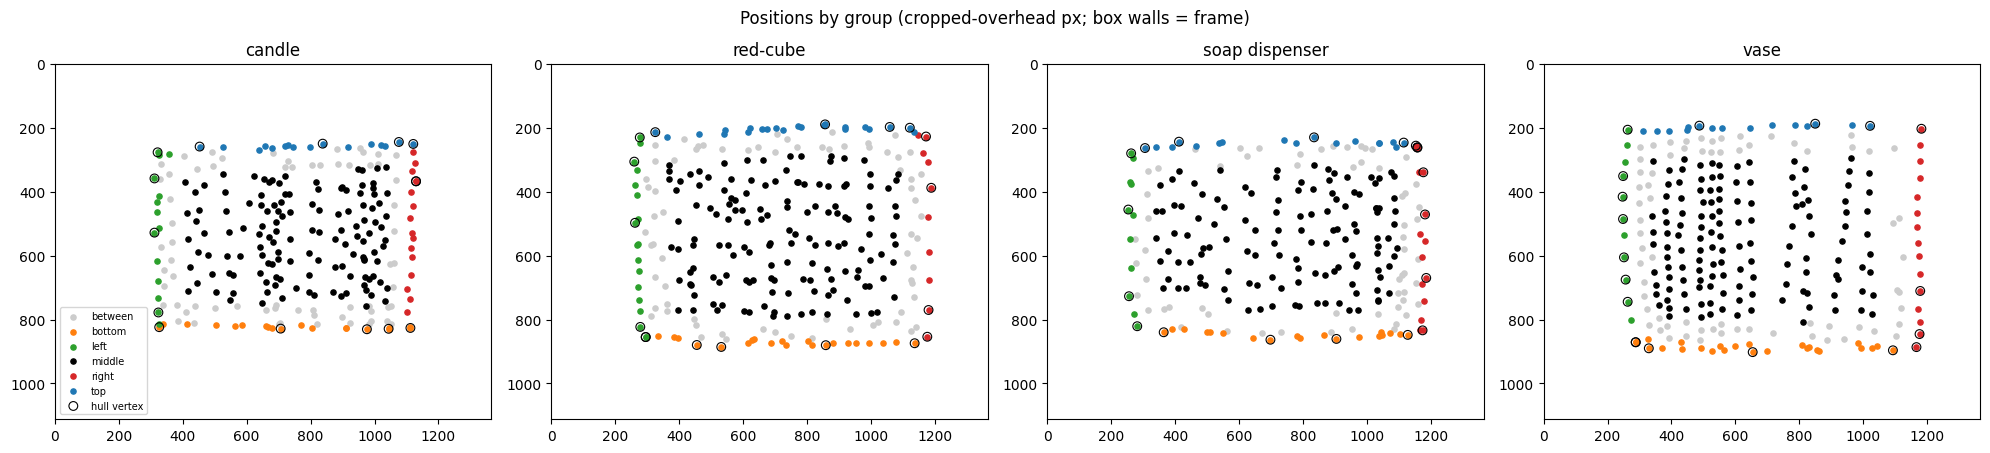

In [4]:
fig, axs = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, obj in zip(axs, OBJECTS):
    p = df[df.object == obj].drop_duplicates("position_id")
    for grp, gg in p.groupby("group"): ax.scatter(gg.com_col, gg.com_row, s=14, c=COLORS[grp], label=grp)
    h = p[p.on_hull]
    ax.scatter(h.com_col, h.com_row, s=40, facecolors="none", edgecolors="k", lw=.8, label="hull vertex")
    ax.set(title=obj, xlim=(0, 1365), ylim=(1112, 0), aspect="equal")
axs[0].legend(fontsize=7, loc="lower left")
plt.suptitle("Positions by group (cropped-overhead px; box walls = frame)")
plt.tight_layout()

# 3 FFTs

`vibration/04_ffts.npz["fft"]` has shape (1, 100 lasers, 1170 freqs over 100-1000 Hz, x/y). Per sample, keep two things in dB (`20 log10 |FFT|`):

- `spec`: the laser-mean spectrum, (1170, 2), for the spectrum plots.
- `feat`: per-laser band means, (100, 39, 2), for the z-score tests. These are 30-bin bands, about 23 Hz each.

Reading all ~5.5k files takes a few minutes, so the result is cached.

In [5]:
samples = pd.concat([df, empty], ignore_index=True)

def load(sid):
    z = np.load(DATA_DIR / "samples" / sid / "vibration" / "04_ffts.npz")
    db = 20 * np.log10(np.abs(z["fft"][0]) + 1e-12)                  # (100, 1170, 2)
    return db.mean(0), db.reshape(100, -1, BAND, 2).mean(2), z["freqs"]

if CACHE.exists() and list(np.load(CACHE)["sample_id"]) == list(samples.sample_id):
    c = np.load(CACHE); spec, feat, freqs = c["spec"], c["feat"], c["freqs"]
else:
    with ThreadPoolExecutor(32) as ex: out = list(ex.map(load, samples.sample_id))
    spec, feat, freqs = np.stack([o[0] for o in out]), np.stack([o[1] for o in out]).astype(np.float32), out[0][2]
    np.savez(CACHE, sample_id=samples.sample_id.to_numpy(str), spec=spec, feat=feat, freqs=freqs)
band_f = freqs.reshape(-1, BAND).mean(1)
print(spec.shape, feat.shape)

(5330, 1170, 2) (5330, 100, 39, 2)


# 4 Is the Edge Signal Weaker?

`loud` is the mean dB over every laser, frequency and axis. Subtract the (object, speaker) median so the speakers line up, then plot the level against hull distance. If edges are "worse" in the sense of quieter, the left side of each panel will dip.

Spearman(d_hull, loud) per object x speaker (positive = edges quieter):


speaker,1,2,3,4,7
object,,,,,
candle,-0.39,-0.44,-0.59,-0.70,-0.30
red-cube,-0.39,-0.50,-0.45,-0.51,-0.33
soap dispenser,-0.45,-0.36,-0.48,-0.52,-0.31
vase,-0.32,-0.31,-0.53,-0.58,-0.41


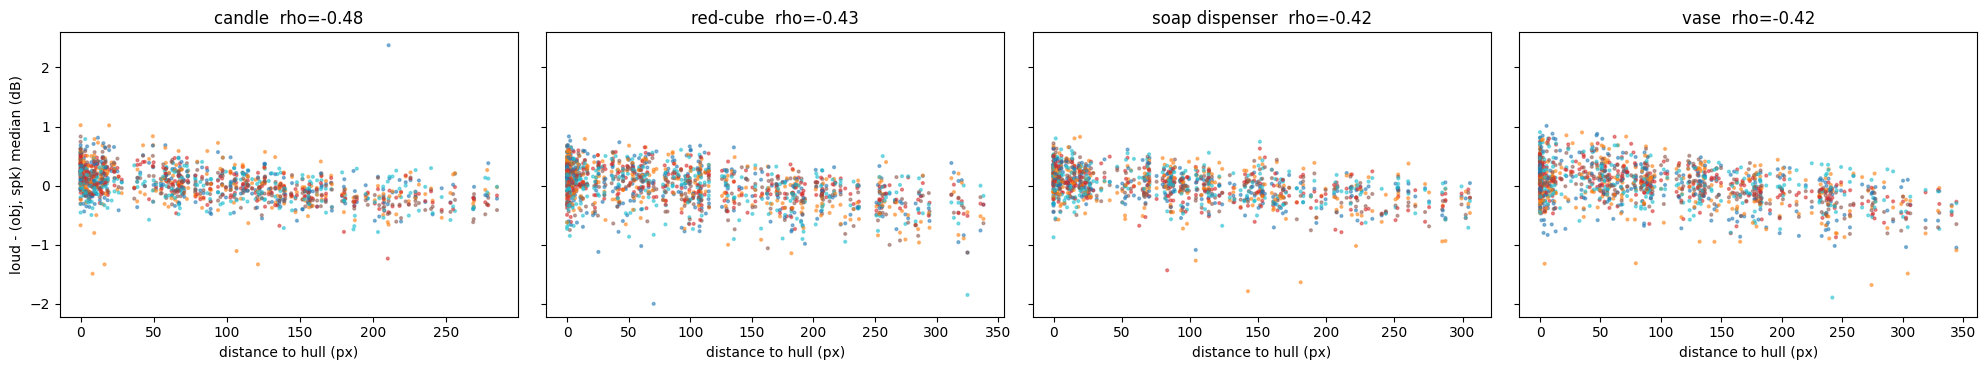

In [6]:
samples["loud"] = feat.reshape(len(feat), -1).mean(1)
obj = samples[samples.object != "empty"].copy()
obj["loud_rel"] = obj.loud - obj.groupby(["object", "speaker"]).loud.transform("median")
emp_level = samples[samples.object == "empty"].groupby("speaker").loud.median()
obj["loud_vs_empty"] = obj.loud - obj.speaker.map(emp_level)

fig, axs = plt.subplots(1, 4, figsize=(20, 3.8), sharey=True)
rows = []
for ax, o in zip(axs, OBJECTS):
    g = obj[obj.object == o]
    ax.scatter(g.d_hull, g.loud_rel, s=4, c=g.speaker, cmap="tab10", alpha=.5)
    rho = spearmanr(g.d_hull, g.loud_rel)[0]
    ax.set(title=f"{o}  rho={rho:+.2f}", xlabel="distance to hull (px)")
    for spk, gs in g.groupby("speaker"): rows.append(dict(object=o, speaker=spk, rho=spearmanr(gs.d_hull, gs.loud_rel)[0]))
axs[0].set_ylabel("loud - (obj, spk) median (dB)")
plt.tight_layout()
print("Spearman(d_hull, loud) per object x speaker (positive = edges quieter):")
pd.DataFrame(rows).pivot(index="object", columns="speaker", values="rho").round(2)

In [7]:
print("Median level by group, dB relative to (obj, spk) median | and relative to the empty box:")
pd.concat([obj.groupby(["object", "group"]).loud_rel.median().unstack()[SIDES + ["middle"]].round(2).add_suffix(""),
           obj.groupby(["object", "group"]).loud_vs_empty.median().unstack()[SIDES + ["middle"]].round(2).add_suffix(" vs empty")], axis=1)

Median level by group, dB relative to (obj, spk) median | and relative to the empty box:


group,top,bottom,left,right,middle,top vs empty,bottom vs empty,left vs empty,right vs empty,middle vs empty
object,,,,,,,,,,
candle,0.01,0.21,0.26,0.06,-0.11,-0.25,-0.04,0.02,-0.22,-0.36
red-cube,0.05,0.04,0.24,0.19,-0.14,-0.05,-0.06,0.11,0.09,-0.27
soap dispenser,0.03,0.26,0.21,0.04,-0.09,-0.15,0.09,0.08,-0.11,-0.29
vase,0.05,0.22,0.26,-0.07,-0.10,-0.10,0.09,0.12,-0.24,-0.28


# 5 Mean Spectrum: Each Side vs Middle

For each (object, speaker): the mean `spec` of each side minus the mean of the middle, in dB, then averaged over speakers. The grey band is ±1 std of individual middle samples around the middle mean. It shows how much a *single* position normally varies. If a side curve stays inside the band, that side is shifted by less than the normal position-to-position spread.

Curves are smoothed over 10 bins (~8 Hz) and use the x and y axes averaged.

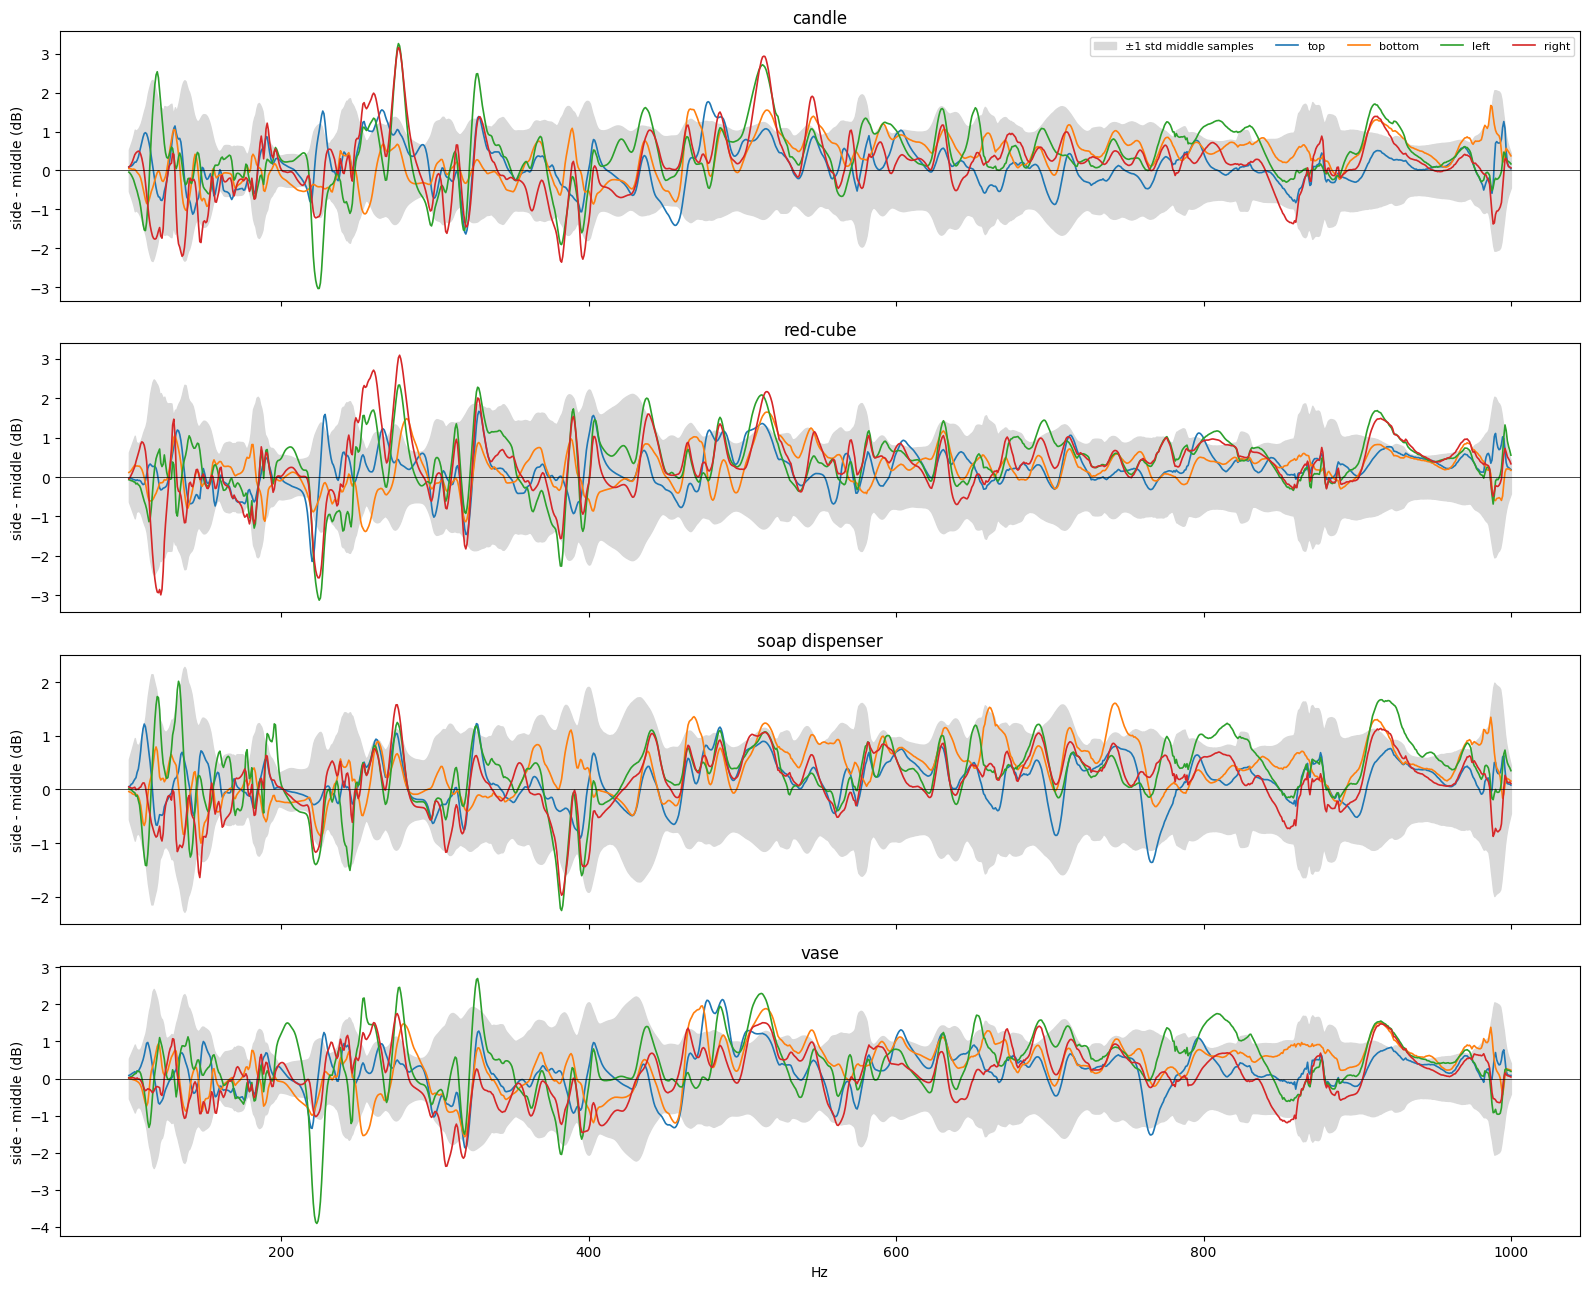

In [8]:
def smooth(a, k=10): return np.convolve(a, np.ones(k) / k, mode="same")
S = spec.mean(-1)                                                       # (N, 1170), x/y averaged

fig, axs = plt.subplots(4, 1, figsize=(16, 13), sharex=True)
for ax, o in zip(axs, OBJECTS):
    diffs, spread = {s: [] for s in SIDES}, []
    for spk in SPEAKERS:
        g = samples[(samples.object == o) & (samples.speaker == spk)]
        mid = S[g.index[g.group == "middle"]]
        spread.append(mid.std(0))
        for s in SIDES: diffs[s].append(S[g.index[g.group == s]].mean(0) - mid.mean(0))
    sd = smooth(np.mean(spread, 0))
    ax.fill_between(freqs, -sd, sd, color="0.85", label="±1 std middle samples")
    for s in SIDES: ax.plot(freqs, smooth(np.mean(diffs[s], 0)), c=COLORS[s], lw=1.2, label=s)
    ax.axhline(0, c="k", lw=.5)
    ax.set(title=o, ylabel="side - middle (dB)")
axs[0].legend(ncol=5, fontsize=8)
axs[-1].set_xlabel("Hz")
plt.tight_layout()

# 6 Distance From the Average, in Std Units

This is the "does it just differ by more than the std" test, run on the per-laser band features. For each (object, speaker), compute `mu` and `sigma` per feature over **all** positions, then z-score every sample. Every sample is in the reference set equally, so edge and middle are compared on equal terms.

- `rmsz`: the RMS of z over all 7800 features. A value of 1 means typical. Above 1 means this position is further from the average than usual.
- Then split each group's RMS² into a **coherent shift**, the group-mean z (every sample on that side moves the same way), and **extra spread**, the within-group std of z (samples on that side are just more scattered).

A large shift with normal spread means the edge is a different but consistent regime. A large spread means the edge is noisier. A small group's mean is noisy too, so `floor = spread / sqrt(n)` is the shift you would see from noise alone. Compare `shift` against it, not against zero.

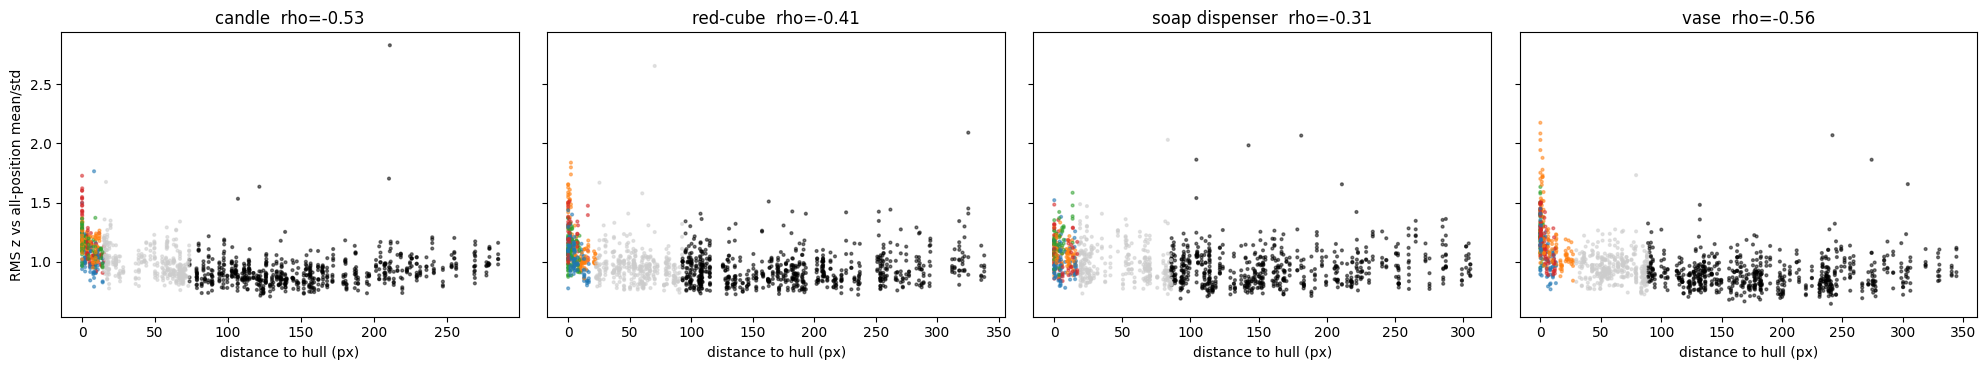

In [9]:
Z = np.zeros((len(samples), feat[0].size), np.float32)
for (o, spk), g in samples[samples.object != "empty"].groupby(["object", "speaker"]):
    F = feat[g.index].reshape(len(g), -1)
    Z[g.index] = (F - F.mean(0)) / F.std(0)
samples["rmsz"] = np.sqrt((Z ** 2).mean(1))
obj = obj.join(samples.rmsz)

fig, axs = plt.subplots(1, 4, figsize=(20, 3.8), sharey=True)
for ax, o in zip(axs, OBJECTS):
    g = obj[obj.object == o]
    ax.scatter(g.d_hull, g.rmsz, s=4, c=[COLORS[x] for x in g.group], alpha=.5)
    ax.set(title=f"{o}  rho={spearmanr(g.d_hull, g.rmsz)[0]:+.2f}", xlabel="distance to hull (px)")
axs[0].set_ylabel("RMS z vs all-position mean/std")
plt.tight_layout()

In [10]:
rows = []
for (o, spk, grp), g in obj[obj.group != "between"].groupby(["object", "speaker", "group"]):
    z = Z[g.index]
    rows.append(dict(object=o, speaker=spk, group=grp, n=len(g), rmsz=np.sqrt((z ** 2).mean()),
                     shift=np.sqrt((z.mean(0) ** 2).mean()), spread=np.sqrt(z.var(0).mean())))
dec = pd.DataFrame(rows)
dec["floor"] = dec.spread / np.sqrt(dec.n)   # shift a group mean of n pure-noise samples would show anyway
dec = dec.groupby(["object", "group"])[["n", "rmsz", "shift", "floor", "spread"]].mean().round(2)
print("rmsz^2 = shift^2 + spread^2 (averaged over speakers). floor = spread/sqrt(n), the shift pure noise would give.")
dec.unstack("group").reorder_levels([1, 0], axis=1)[SIDES + ["middle"]]

rmsz^2 = shift^2 + spread^2 (averaged over speakers). floor = spread/sqrt(n), the shift pure noise would give.


group            top                          bottom                           \
                   n  rmsz shift floor spread      n  rmsz shift floor spread   
object                                                                          
candle          16.0  1.06  0.49  0.24   0.95   19.0  1.15  0.47  0.24   1.05   
red-cube        22.0  1.04  0.46  0.20   0.94   21.0  1.19  0.44  0.24   1.10   
soap dispenser  17.0  1.00  0.42  0.22   0.91   19.0  1.08  0.51  0.22   0.94   
vase            15.0  1.06  0.48  0.24   0.95   26.0  1.24  0.50  0.22   1.13   

group           ... right                          middle                    \
                ...     n  rmsz shift floor spread      n  rmsz shift floor   
object          ...                                                           
candle          ...  16.0  1.18  0.68  0.24   0.96  130.0  0.93  0.21  0.08   
red-cube        ...  10.0  1.21  0.67  0.32   1.01  141.0  0.94  0.20  0.08   
soap dispenser  ...  15.0  1.07  0.55  0.24   0.92  123.0  0.96  0.19  0.08   
vase            ...  15.0  1.18  0.65  0.25   0.98  134.0  0.91  0.21  0.08   

group                  
               spread  
object                 
candle           0.90  
red-cube         0.92  
soap dispenser   0.94  
vase             0.88  

[4 rows x 25 columns]

# 7 Distance From the Empty Box

"Worse" could also mean the object cue gets weaker: an object against the wall might barely change the box response. Z-score every object sample against the empty-box captures of its speaker (~12 per speaker), using a MAD-based sigma with a floor so the small reference set doesn't blow up. `cue` is the RMS of that z. A larger `cue` means the object moves the spectrum further from the empty box.

group,top,bottom,left,right,middle
object,,,,,
candle,2.51,2.65,2.47,2.45,2.48
red-cube,2.29,2.55,2.48,2.62,2.29
soap dispenser,2.26,2.48,2.38,2.02,2.35
vase,2.42,2.55,2.90,2.46,2.42


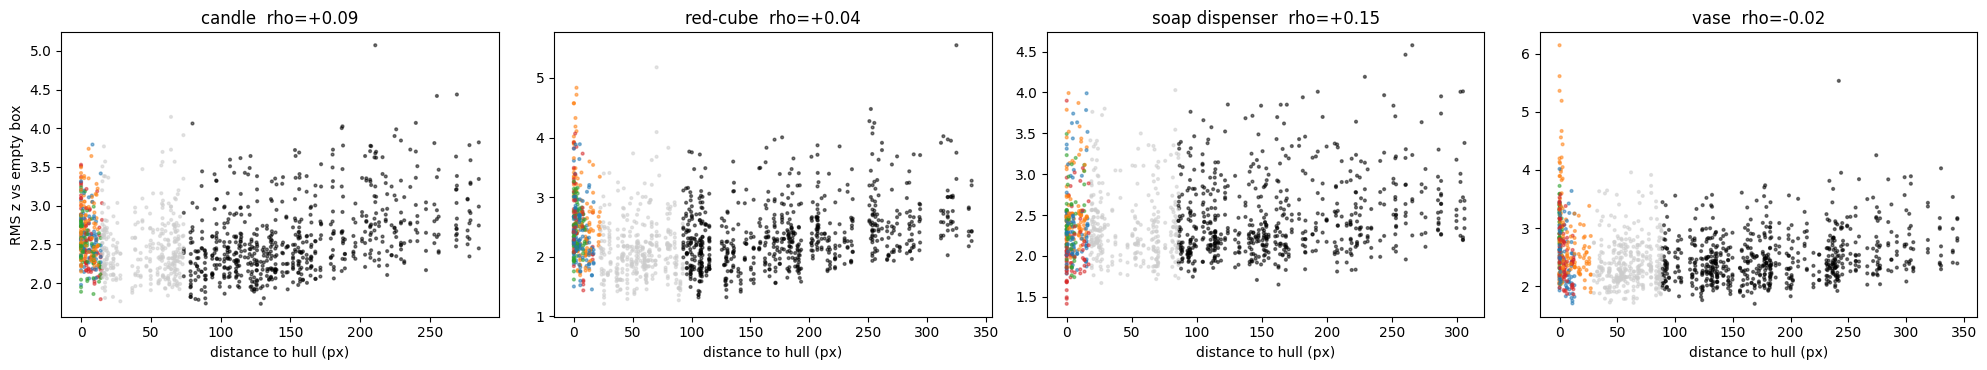

In [11]:
for spk in SPEAKERS:
    e = feat[samples.index[(samples.object == "empty") & (samples.speaker == spk)]].reshape(-1, Z.shape[1])
    mu = np.median(e, 0)
    sig = np.maximum(1.4826 * np.median(np.abs(e - mu), 0), 0.5)          # >= 0.5 dB floor
    idx = obj.index[obj.speaker == spk]
    obj.loc[idx, "cue"] = np.sqrt((((feat[idx].reshape(len(idx), -1) - mu) / sig) ** 2).mean(1))

fig, axs = plt.subplots(1, 4, figsize=(20, 3.8))
for ax, o in zip(axs, OBJECTS):
    g = obj[obj.object == o]
    ax.scatter(g.d_hull, g.cue, s=4, c=[COLORS[x] for x in g.group], alpha=.5)
    ax.set(title=f"{o}  rho={spearmanr(g.d_hull, g.cue)[0]:+.2f}", xlabel="distance to hull (px)")
axs[0].set_ylabel("RMS z vs empty box")
plt.tight_layout()
obj.groupby(["object", "group"]).cue.median().unstack()[SIDES + ["middle"]].round(2)

# 8 Local Consistency

The question that matters for learning: is an edge position's spectrum still **predictable from its neighbours**? For each sample, compute its feature distance (RMS of the z difference) to the K=4 nearest positions in space, then divide by its median distance to every other position with the same (object, speaker). A ratio well below 1 means the spectrum varies smoothly with position. A ratio near 1 means the neighbours are no more alike than random positions, so the spectrum there carries little position information.

group,top,bottom,left,right,middle
object,,,,,
candle,0.74,0.71,0.69,0.76,0.73
red-cube,0.81,0.91,0.78,0.91,0.85
soap dispenser,0.74,0.72,0.82,0.75,0.79
vase,0.66,0.66,0.71,0.67,0.59


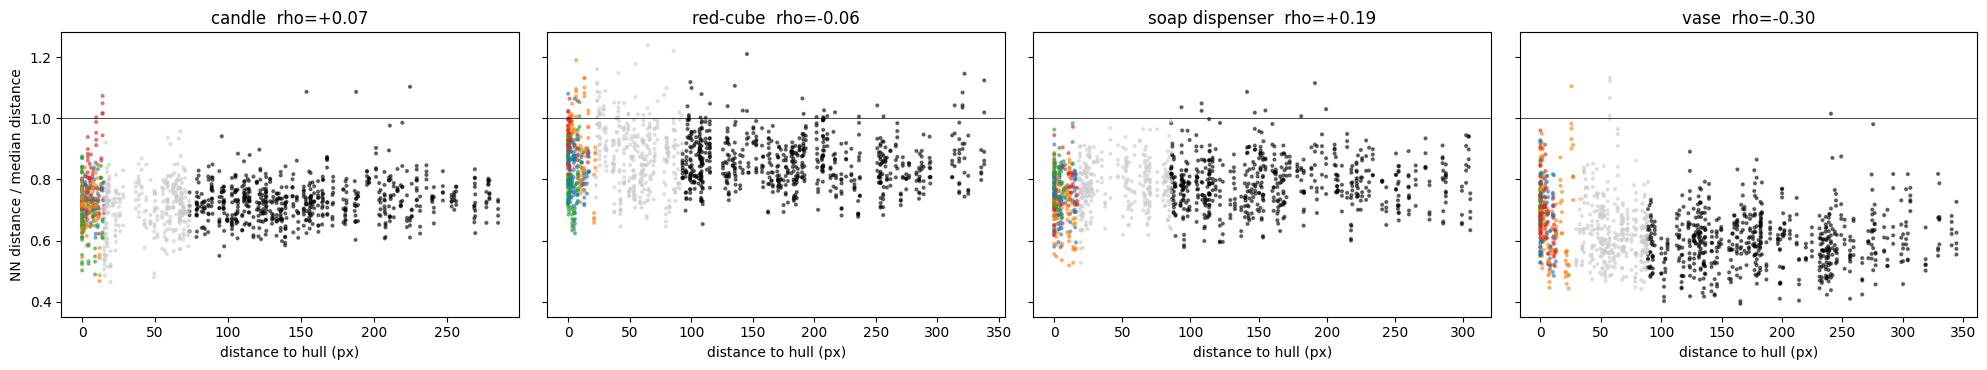

In [12]:
K = 4
for (o, spk), g in obj.groupby(["object", "speaker"]):
    z = Z[g.index]
    D = np.sqrt(np.maximum((z ** 2).mean(1)[:, None] + (z ** 2).mean(1)[None] - 2 * z @ z.T / z.shape[1], 0))
    _, nn = cKDTree(g[["com_col", "com_row"]].to_numpy()).query(g[["com_col", "com_row"]].to_numpy(), K + 1)
    near = np.take_along_axis(D, nn[:, 1:], 1).mean(1)
    np.fill_diagonal(D, np.nan)
    obj.loc[g.index, "local"] = near / np.nanmedian(D, 1)

fig, axs = plt.subplots(1, 4, figsize=(20, 3.8), sharey=True)
for ax, o in zip(axs, OBJECTS):
    g = obj[obj.object == o]
    ax.scatter(g.d_hull, g.local, s=4, c=[COLORS[x] for x in g.group], alpha=.5)
    ax.axhline(1, c="k", lw=.5)
    ax.set(title=f"{o}  rho={spearmanr(g.d_hull, g.local)[0]:+.2f}", xlabel="distance to hull (px)")
axs[0].set_ylabel("NN distance / median distance")
plt.tight_layout()
obj.groupby(["object", "group"]).local.median().unstack()[SIDES + ["middle"]].round(2)

# 9 Where in Frequency Does the Edge Differ?

Per band, the RMS over lasers and axes of the group-mean z: the coherent shift from section 6, resolved by frequency. Bands where a side climbs well above the middle are where the edge regime lives.

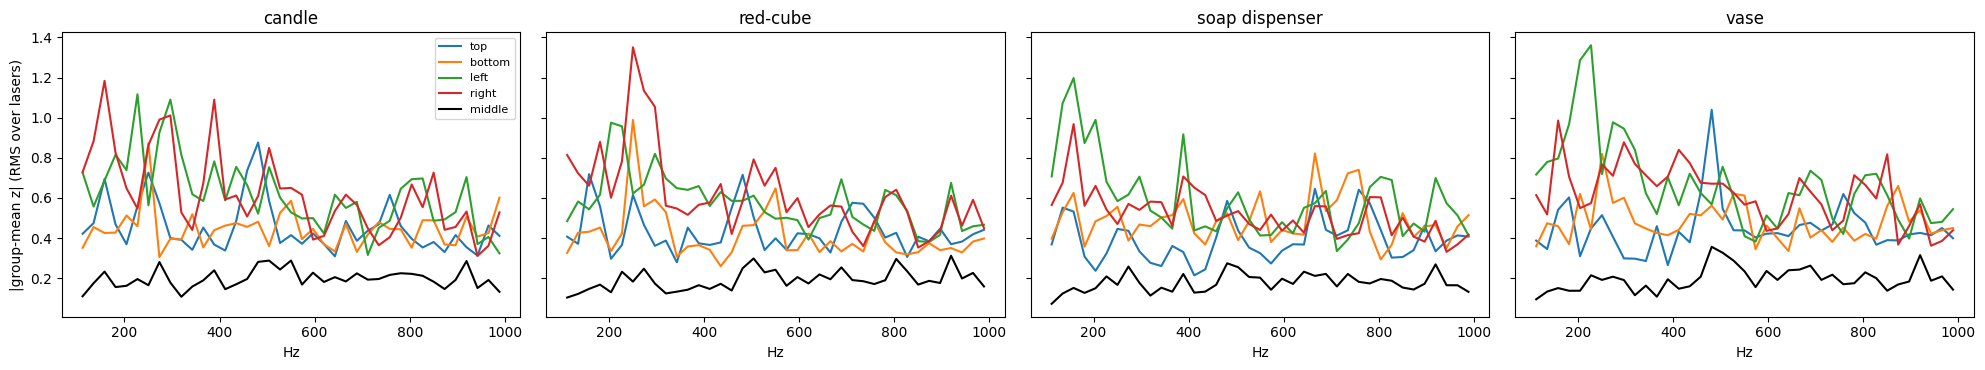

In [13]:
fig, axs = plt.subplots(1, 4, figsize=(20, 3.8), sharey=True)
for ax, o in zip(axs, OBJECTS):
    for grp in SIDES + ["middle"]:
        shifts = []
        for spk in SPEAKERS:
            z = Z[obj.index[(obj.object == o) & (obj.speaker == spk) & (obj.group == grp)]].reshape(-1, 100, len(band_f), 2)
            shifts.append(np.sqrt((z.mean(0) ** 2).mean((0, 2))))
        ax.plot(band_f, np.mean(shifts, 0), c=COLORS[grp], label=grp)
    ax.set(title=o, xlabel="Hz")
axs[0].set_ylabel("|group-mean z| (RMS over lasers)")
axs[0].legend(fontsize=8)
plt.tight_layout()

# 10 Summary

In [14]:
s = obj.assign(edge=obj.group.isin(SIDES))[obj.group != "between"].groupby(["object", "edge"])[["loud_rel", "rmsz", "cue", "local"]].median().unstack().round(2)
s.columns = [f"{a} ({'edge' if b else 'middle'})" for a, b in s.columns]
s

,loud_rel (middle),loud_rel (edge),rmsz (middle),rmsz (edge),cue (middle),cue (edge),local (middle),local (edge)
object,,,,,,,,
candle,-0.11,0.14,0.90,1.11,2.48,2.51,0.73,0.73
red-cube,-0.14,0.14,0.91,1.09,2.29,2.45,0.85,0.86
soap dispenser,-0.09,0.12,0.93,1.07,2.35,2.33,0.79,0.74
vase,-0.10,0.13,0.88,1.14,2.42,2.56,0.59,0.68


## Findings (2026-10-08)

**Edges are not worse. They are a different, consistent regime.**

1. **Not weaker, slightly louder.** Spearman(hull distance, level) is negative in all 20 (object, speaker) pairs (-0.30 to -0.70), so the edges are about 0.25 dB louder than the middle. Objects in the middle damp the box by about 0.3 dB relative to the empty box, while edge objects sit near the empty-box level.
2. **Further from the average, mostly as a coherent shift.** RMS z is 1.07-1.14 at the edges vs 0.88-0.93 in the middle. The edge groups shift by 0.42-0.72 against a noise floor of about 0.24, while the spread rises only 0-20% (bottom and vase rise the most).
3. **The shift lives in the low modes.** Left and right differ most below about 350 Hz. Individual side curves reach ±3 dB near 220 and 275 Hz.
4. **The object cue is not weaker.** RMS z against the empty box is the same or slightly higher at the edges.
5. **Edge positions are still locally predictable.** The NN/median distance ratio is the same at the edges as in the middle (candle .73/.73, red-cube .86/.85, soap .74/.79). Vase is the exception, with edges worse at .68 vs .59.

So for a model, the edge is a separate spectral regime that covers only about 25% of positions, split across 4 sides (about 10-25 positions per side per object). It is under-represented, not corrupted.